# Reference audit — flagged plots vs NAREI (2020)

Some CEO plots were flagged during interpretation (left unlabelled), in
regions the interpreter was less sure of. This notebook populates every flagged plot by
comparing it against NAREI's independent 2020 regional mangrove extent maps
(`mangroves.gov.gy`), then writes the decisions into the main accuracy sheet.

The flow involves detecting the regions containing flagged plots,
downloading those NAREI extents, and building a single combined worksheet.

Note: Model predictions are deliberately excluded to preserve the independence of the assessment. The audit sees only CEO, NAREI, and interpretations in Planet for reference. 

Also NAREI is 2020, CEO/Planet is 2021 — a minor source of disagreement, so
NAREI is simply an aid for comparison, not new ground truth.

In [12]:
import sys
from pathlib import Path

sys.path.insert(0, "../../")

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mangrove_mapper.utils.regions import load_regions

DATA = Path("../../data")
AA = Path(".")

CEO_CSV = AA / "ceo-coastwide-interpretations-plot-data-2026-08-14.csv" # downloadable from the CEO website (https://app.collect.earth/review-project?projectId=62895)
REGIONS = DATA / "guyana_regions.geojson"

# NAREI 2020 regional mangrove extents: one zip per region, same URL pattern
NAREI_URL_TMPL = "https://www.mangroves.gov.gy/media/spatial_uploads/{code}_2020.zip"
REGION_CODE = {
    "Barima-Waini": "R1",
    "Pomeroon-Supenaam": "R2",
    "Essequibo Islands-West Demerara": "R3",
    "Demerara-Mahaica": "R4",
    "Mahaica-Berbice": "R5",
    "East Berbice-Corentyne": "R6",
}
WORK_CRS = "EPSG:32621"   # UTM 21N (metres) — project everything here


## 1. Load CEO interpretations

CEO stores each answer as two percentage columns. With one sample point per plot a call is
`:1 == 100` (mangrove) or `:0 == 100` (non-mangrove). A flagged plot has neither set — it
was flagged instead of answered, so its label is left N/A. The flagged plots will be
populated below.

In [13]:
ceo = pd.read_csv(CEO_CSV)

C1 = "Is it mangrove (1) or not? (0):1"
C0 = "Is it mangrove (1) or not? (0):0"
ceo["ceo_label"] = np.where(ceo[C1] == 100, 1.0,
                            np.where(ceo[C0] == 100, 0.0, np.nan))
ceo.loc[ceo["flagged"] == True, "ceo_label"] = np.nan   # flagged is never treated as labelled

ceo = ceo.rename(columns={"center_lon": "LON", "center_lat": "LAT", "plotid": "PLOTID"}) # default columns to match full coast accuracy assessment csv
ceo = ceo[["PLOTID", "LON", "LAT", "ceo_label", "pl_planet_label",
           "confidence", "flagged", "flagged_reason"]] 

print(f"{len(ceo)} plots | labelled {int(ceo['ceo_label'].notna().sum())} | "
      f"flagged {int((ceo['flagged'] == True).sum())}")


600 plots | labelled 488 | flagged 112


## 2. Determine which regions need a NAREI extent map

Assign every flagged plot to its nearest coastal region (plots a few hundred
metres offshore are kept). The regions that
actually contain flagged plots are exactly the NAREI extents to download.

In [14]:
regions = load_regions(REGIONS).to_crs(WORK_CRS)

flag = ceo[ceo["flagged"] == True].copy()
fg = gpd.GeoDataFrame(
    flag, geometry=gpd.points_from_xy(flag["LON"], flag["LAT"], crs="EPSG:4326"),
).to_crs(WORK_CRS)

tag = gpd.sjoin_nearest(fg, regions[["shapeName", "geometry"]], how="left")
tag = tag[~tag.index.duplicated(keep="first")]
fg["region"] = tag["shapeName"].values

counts = fg["region"].value_counts()
NEEDED = [r for r in counts.index if r in REGION_CODE]
unknown = [r for r in counts.index if r not in REGION_CODE]

print("flagged plots per region:")
for r in NEEDED:
    print(f"  {REGION_CODE[r]}  {r:34} {counts[r]:3d}")
if unknown:
    print("  ! flagged plots with no NAREI region (skipped):", unknown)
print(f"\nNAREI extents required: {[REGION_CODE[r] for r in NEEDED]}")


flagged plots per region:
  R1  Barima-Waini                        97
  R6  East Berbice-Corentyne              10
  R5  Mahaica-Berbice                      3
  R2  Pomeroon-Supenaam                    2

NAREI extents required: ['R1', 'R6', 'R5', 'R2']


## 3. Download + load the needed NAREI extents

Fetch directly from the NAREI portal and unzip locally (once, then reused), so the
notebook reproduces from nothing. Each region's file holds `DN = 1` mangrove polygons.

In [15]:
import urllib.request
import zipfile


def load_narei(code):
    """Download+unzip {code}_2020 once; return (polygons_gdf, dissolved_geom) in WORK_CRS."""
    ndir = DATA / f"{code}_2020"
    shp = ndir / f"{code}_2020.shp"
    if not shp.exists():
        ndir.mkdir(parents=True, exist_ok=True)
        zp = DATA / f"{code}_2020.zip"
        url = NAREI_URL_TMPL.format(code=code)
        print(f"downloading {url}")
        # the portal 403s urllib's default agent, so sending a browser User-Agent
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as resp:
            zp.write_bytes(resp.read())
        with zipfile.ZipFile(zp) as z:
            z.extractall(ndir)
    g = gpd.read_file(shp).to_crs(WORK_CRS)
    g = g[g["DN"] == 1]
    return g, g.union_all()


narei_gdf, narei_geom = {}, {}
for reg in NEEDED:
    narei_gdf[reg], narei_geom[reg] = load_narei(REGION_CODE[reg])
    print(f"{REGION_CODE[reg]} ({reg}): {len(narei_gdf[reg])} mangrove polygons")


R1 (Barima-Waini): 731 mangrove polygons
R6 (East Berbice-Corentyne): 218 mangrove polygons
R5 (Mahaica-Berbice): 102 mangrove polygons
R2 (Pomeroon-Supenaam): 331 mangrove polygons


## 4. NAREI context per flagged plot + combined worksheet

For each flagged plot, against **its own region's** NAREI extent: `in_narei` (inside a
polygon?) and `dist_narei_m` (metres to the nearest polygon, 0 inside, a few metres = fringe
edge, hundreds = clearly outside). One worksheet across all regions, sorted region then
distance, with a Google Earth link and a blank `corrected_label`.

In [18]:
parts = []
for reg in NEEDED:
    sub = fg[fg["region"] == reg].copy()
    geom = narei_geom[reg]
    sub["narei_code"] = REGION_CODE[reg]
    sub["in_narei"] = sub.geometry.within(geom)
    sub["dist_narei_m"] = sub.geometry.distance(geom).round(1)
    sub["narei_label"] = sub["in_narei"].astype(int)
    parts.append(sub)
flagged = gpd.GeoDataFrame(pd.concat(parts), crs=WORK_CRS)

flagged["google_earth"] = flagged.apply(
    lambda r: f"https://earth.google.com/web/@{r.LAT:.6f},{r.LON:.6f},0a,500d,35y,0h,0t,0r", axis=1)

cols = ["PLOTID", "region", "narei_code", "LON", "LAT", "confidence", "flagged_reason",
        "in_narei", "dist_narei_m", "narei_label", "pl_planet_label", "google_earth"]
work = (pd.DataFrame(flagged.drop(columns="geometry"))[cols]
        .sort_values(["region", "dist_narei_m"]).reset_index(drop=True))
work["corrected_label"] = pd.NA

WORKSHEET = AA / "flagged_worksheet.csv"
work.to_csv(WORKSHEET, index=False)
print(f"{len(work)} flagged plots across {len(NEEDED)} regions found in: {WORKSHEET.name}")
work


112 flagged plots across 4 regions found in: flagged_worksheet.csv


,PLOTID,region,narei_code,LON,LAT,confidence,flagged_reason,in_narei,dist_narei_m,narei_label,pl_planet_label,google_earth,corrected_label
0,305,Barima-Waini,R1,-59.341980,8.155480,NaN,"Looks like mangrove, not sure",True,0.0,1,1,"https://earth.google.com/web/@8.155480,-59.341...",<NA>
1,318,Barima-Waini,R1,-59.319811,8.149100,NaN,"Looks like mangrove, not 100% sure",True,0.0,1,1,"https://earth.google.com/web/@8.149100,-59.319...",<NA>
2,345,Barima-Waini,R1,-59.291328,8.133083,NaN,double check this,True,0.0,1,1,"https://earth.google.com/web/@8.133083,-59.291...",<NA>
3,411,Barima-Waini,R1,-59.299701,8.138007,NaN,mangrove?,True,0.0,1,1,"https://earth.google.com/web/@8.138007,-59.299...",<NA>
4,416,Barima-Waini,R1,-59.343532,8.157279,NaN,NaN,True,0.0,1,0,"https://earth.google.com/web/@8.157279,-59.343...",<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...
107,485,Mahaica-Berbice,R5,-57.776697,6.573746,NaN,Mangroves?,False,168.3,0,0,"https://earth.google.com/web/@6.573746,-57.776...",<NA>
108,150,Mahaica-Berbice,R5,-57.574040,6.374652,NaN,Mangrove?,False,259.8,0,0,"https://earth.google.com/web/@6.374652,-57.574...",<NA>
109,428,Mahaica-Berbice,R5,-57.668934,6.479104,NaN,Mangrove?,False,836.5,0,0,"https://earth.google.com/web/@6.479104,-57.668...",<NA>
110,329,Pomeroon-Supenaam,R2,-58.668756,7.577962,NaN,Not sure if mangrove or not,True,0.0,1,1,"https://earth.google.com/web/@7.577962,-58.668...",<NA>


## 5. Decisions

`PLOTID yields class` (1 mangrove, 0 non-mangrove). Either populate the dictionary directly or make your corrected plots in `flagged_worksheet.csv` and port them over to this dictionary. Decisions were made by referencing the CEO Sentinel 2 imagery, Google Earth High Res and comparing to the NAREI 2020 extent map. Most flagged plots ended up being congruent with the NAREI 2020 designations, given there's only a one-year gap between the NAREI extent (2020) and the CEO interpretation (2021). Note, decisions live in the notebook, so they persist without committing the
worksheet CSV.

In [20]:
DECISIONS = {
    # Region 1 (Barima-Waini), audited against R1_2020
    # mangrove (inside NAREI extent)
    462: 1, 411: 1, 416: 1, 569: 1, 318: 1, 532: 1, 305: 1, 423: 1,
    495: 1, 484: 1, 481: 1, 435: 1, 345: 1, 537: 1, 578: 1,
    # non-mangrove (outside NAREI extent)
    388: 0, 525: 0, 336: 0, 398: 0, 590: 0, 427: 0, 303: 0, 497: 0,
    467: 0, 393: 0, 114: 0, 554: 0, 422: 0, 455: 0, 598: 0, 472: 0,
    566: 0, 381: 0, 505: 0, 570: 0, 419: 0, 363: 0, 223: 0, 490: 0,
    369: 0, 565: 0, 186: 0, 588: 0, 589: 0, 454: 0, 547: 0, 301: 0,
    439: 0, 399: 0, 257: 0, 461: 0, 391: 0, 138: 0, 153: 0, 334: 0,
    337: 0, 438: 0, 189: 0, 181: 0, 400: 0, 575: 0, 172: 0, 459: 0,
    531: 0, 164: 0, 384: 0, 70: 0, 377: 0, 406: 0, 409: 0, 576: 0,
    545: 0, 592: 0, 562: 0, 526: 0, 474: 0, 550: 0, 597: 0, 370: 0,
    585: 0, 335: 0, 408: 0, 403: 0, 383: 0, 22: 0, 476: 0, 511: 0,
    457: 0, 254: 0, 573: 0, 477: 0, 559: 0, 178: 0, 523: 0, 170: 0,
    420: 0, 491: 0,
    # Pomeroon-Supenaam (R2_2020)
    329: 1, 546: 0,
    # Mahaica-Berbice (R5_2020)
    485: 0, 150: 0, 428: 0,
    # East Berbice-Corentyne (R6_2020)
    551: 1, 581: 1, 407: 0, 561: 0, 344: 0, 125: 0, 72: 0, 376: 0, 437: 0, 396: 0,
}

bad = sorted(set(DECISIONS.values()) - {0, 1})
extra = sorted(set(DECISIONS) - set(work["PLOTID"]))
assert not bad, f"labels must be 0 or 1, got {bad}"
assert not extra, f"PLOTID(s) not in the flagged set: {extra}"

work["corrected_label"] = work["PLOTID"].map(DECISIONS).astype("Int64")
work.to_csv(WORKSHEET, index=False)

undecided = work[work["corrected_label"].isna()]
print(f"decided {len(work) - len(undecided)}/{len(work)}")
if len(undecided):
    print("still to decide, by region:")
    for reg, g in undecided.groupby("region"):
        print(f"  {reg}: {g['PLOTID'].tolist()}")


decided 112/112


## 6. Overlay per region — undecided plots highlighted

One map per region: NAREI mangrove polygons with the flagged plots. Undecided plots are
large and red with their PLOTID. Prior decided plots are small (green inside NAREI, grey
outside).

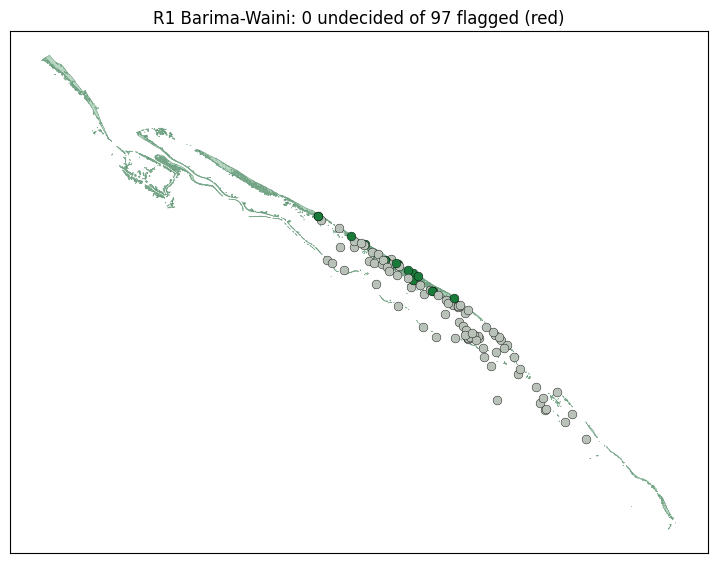

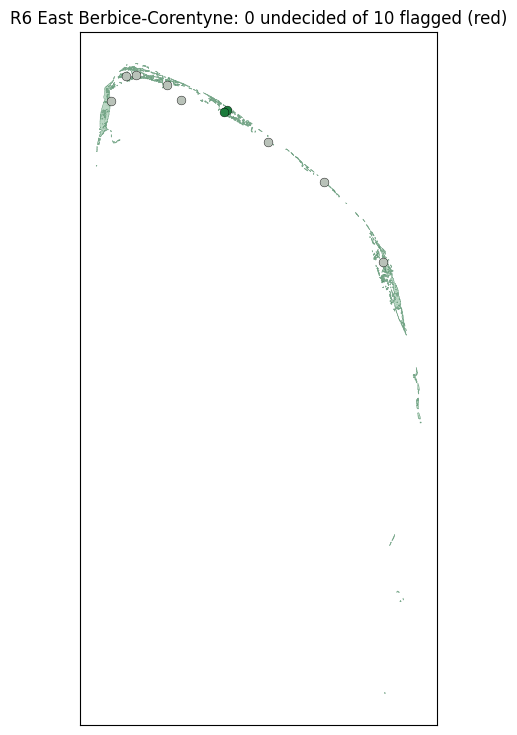

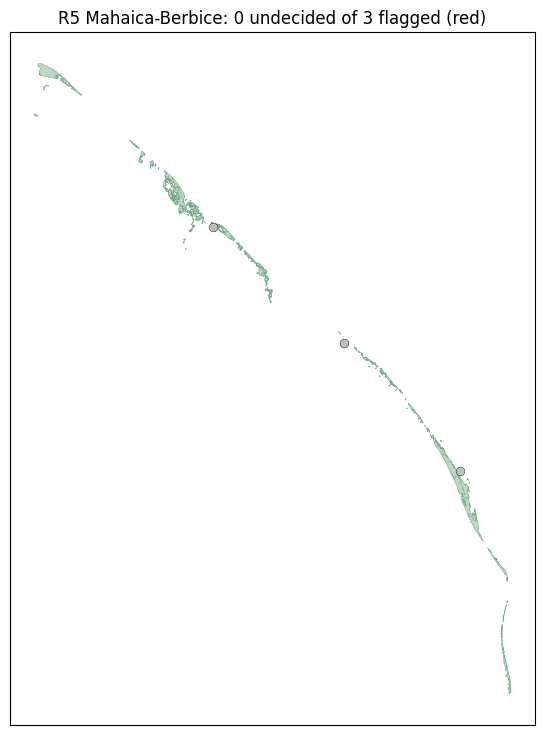

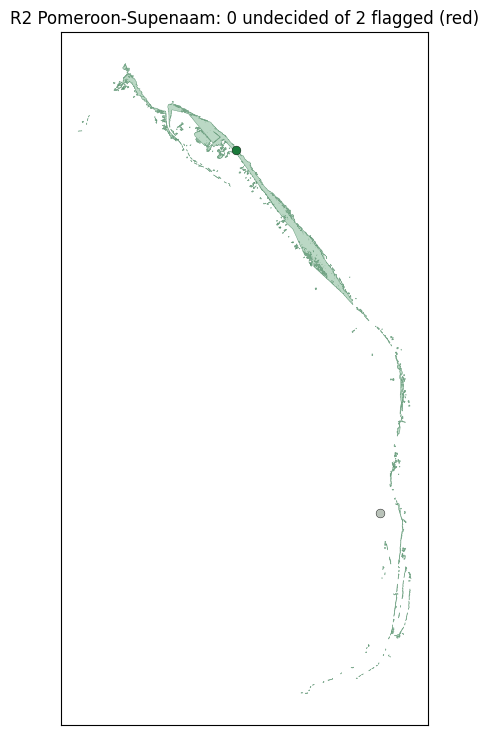

In [22]:
for reg in NEEDED:
    sub = flagged[flagged["region"] == reg]
    fig, ax = plt.subplots(figsize=(9, 9))
    narei_gdf[reg].plot(ax=ax, color="#8fbf9f", edgecolor="#3a7d54", linewidth=0.3, alpha=0.6)
    for _, r in sub.iterrows():
        undec = int(r["PLOTID"]) not in DECISIONS
        ax.scatter(r.geometry.x, r.geometry.y,
                   s=(120 if undec else 40),
                   c=("#d73027" if undec else ("#1a7a3a" if r["narei_label"] else "#b9c2b9")),
                   edgecolor="black", linewidth=(1.3 if undec else 0.3), zorder=3)
        if undec:
            ax.annotate(str(int(r["PLOTID"])), (r.geometry.x, r.geometry.y),
                        xytext=(4, 4), textcoords="offset points", fontsize=8, zorder=4)
    n_und = int(sum(int(p) not in DECISIONS for p in sub["PLOTID"]))
    ax.set_title(f"{REGION_CODE[reg]} {reg}: {n_und} undecided of {len(sub)} flagged (red)")
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    # plt.savefig(DATA / f"flagged_over_narei_{REGION_CODE[reg]}.png", dpi=150, bbox_inches="tight")
    plt.show()


## 7. Per-plot zoom — undecided plots only

One 300 m panel per **undecided** plot, showing exactly where it sits on its region's NAREI
polygons. Read alongside the Google Earth link in the worksheet. When every plot is decided
this cell reports nothing left.

In [23]:
undec = flagged[~flagged["PLOTID"].isin(DECISIONS)].reset_index(drop=True)
BUF = 300   # metres around each plot

if len(undec) == 0:
    print("no undecided flagged plots — all done")
else:
    ncol = min(4, len(undec))
    nrow = int(np.ceil(len(undec) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 3.2 * nrow), squeeze=False)
    for k, (_, r) in enumerate(undec.iterrows()):
        ax = axes[k // ncol][k % ncol]
        cx, cy = r.geometry.x, r.geometry.y
        local = narei_gdf[r["region"]].clip(r.geometry.buffer(BUF).envelope)
        if not local.empty:
            local.plot(ax=ax, color="#8fbf9f", edgecolor="#3a7d54", linewidth=0.5, alpha=0.7)
        ax.scatter(cx, cy, s=80, c="#d73027", edgecolor="black", linewidth=1.2, zorder=5)
        ax.set_xlim(cx - BUF, cx + BUF); ax.set_ylim(cy - BUF, cy + BUF)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        tag = "in NAREI" if r["in_narei"] else f"{r['dist_narei_m']:.0f} m out"
        ax.set_title(f"{r['narei_code']} plot {int(r['PLOTID'])} ({tag})", fontsize=8)
    for k in range(len(undec), nrow * ncol):
        axes[k // ncol][k % ncol].axis("off")
    fig.suptitle("Undecided flagged plots — NAREI polygons within 300 m", fontsize=12)
    plt.tight_layout()
    # plt.savefig(DATA / "flagged_zoom_undecided.png", dpi=150, bbox_inches="tight")
    plt.show()


no undecided flagged plots — all done


## 8. Write CEO interpretations into the main accuracy sheet

Transfer CEO calls into `full_coast_accuracy_assessment_final.csv`: every non-flagged plot
takes its CEO answer, every flagged plot takes its final `DECISIONS` value. Undecided
flagged plots are left blank. Written labels are dated in `entry_date_ceo`;
`planet_label` is not touched.

In [ ]:
from datetime import datetime, timezone

MAIN = AA / "full_coast_accuracy_assessment_final.csv"
TODAY = datetime.now(timezone.utc).date().isoformat()

ceo_full = ceo.set_index("PLOTID")["ceo_label"].astype("Float64").copy()
for pid, lab in DECISIONS.items():
    ceo_full.loc[pid] = lab

main = pd.read_csv(MAIN)
missing = set(main["PLOTID"]) - set(ceo_full.index)
assert not missing, f"main sheet has PLOTIDs absent from the CEO export: {sorted(missing)[:5]}"

prev_date = main["entry_date_ceo"] if "entry_date_ceo" in main.columns else pd.NA
main["ceo_label"] = main["PLOTID"].map(ceo_full).astype("Int64")
main["entry_date_ceo"] = np.where(main["ceo_label"].notna(), TODAY, prev_date)
main.to_csv(MAIN, index=False)

print(f"wrote {int(main['ceo_label'].notna().sum())}/{len(main)} ceo_labels -> {MAIN.name} (dated {TODAY})")
print(f"still pending (flagged, undecided): {int(main['ceo_label'].isna().sum())}")
